In [ ]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import *
RS = 42
df = pd.read_csv("Bengaluru_House_Data.csv")
print(df.shape); print(df.isna().mean().mul(100).round(1))
df.info()

(13320, 9)
area_type        0.0
availability     0.0
location         0.0
size             0.1
society         41.3
total_sqft       0.0
bath             0.5
balcony          4.6
price            0.0
dtype: float64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [ ]:
from google.colab import files

uploaded = files.upload()
# After uploading, you will be able to run your data loading step.

Saving Bengaluru_House_Data.csv to Bengaluru_House_Data.csv


In [ ]:
import re
def to_sqft(x):
    try: return float(x)
    except:
        s = str(x)
        if '-' in s:
            a,b = s.split('-')[:2]
            try: return (float(a)+float(b))/2
            except: return np.nan
        m = re.match(r"([\d.]+)\s*(Sq\. Meter|Sq\. Yards|Perch|Acres|Cents|Guntha|Grounds)", s)
        if m:
            f = {'Sq. Meter':10.7639,'Sq. Yards':9,'Perch':272.25,'Acres':43560,
                 'Cents':435.6,'Guntha':1089,'Grounds':2400}[m.group(2)]
            return float(m.group(1))*f
        return np.nan

df = df.drop(columns=['society'])                      # >40% missing -> justify in paper
df['sqft'] = df['total_sqft'].apply(to_sqft)
df['bhk'] = df['size'].str.extract(r'(\d+)').astype(float)
df['location'] = df['location'].str.strip()
df = df.dropna(subset=['sqft','bhk','price','location'])
df['price_per_sqft'] = df['price']*1e5/df['sqft']
df['ready'] = (df['availability']=='Ready To Move').astype(int)

# rule-based removal of impossible records (document counts in the paper)
n0 = len(df)
df = df[(df['sqft']/df['bhk']>=300) & (df['bath']<=df['bhk']+2)]
print("removed", n0-len(df))
df['affordable'] = (df['price']<=45).astype(int)
print(df['affordable'].mean())

removed 814
0.20177756425654575


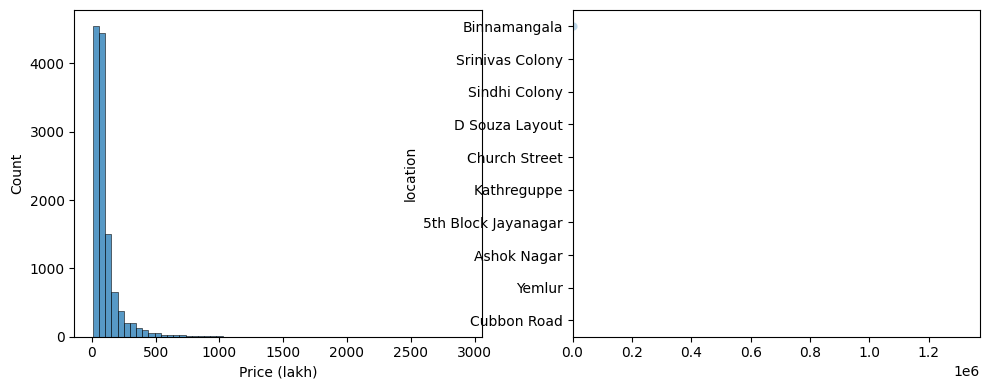

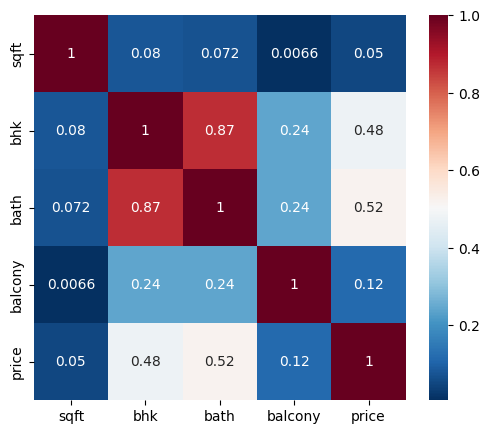

In [ ]:
fig,ax=plt.subplots(1,2,figsize=(10,4))
sns.histplot(df.price,bins=60,ax=ax[0]); ax[0].set_xlabel("Price (lakh)")
sns.scatterplot(x='sqft',y='price',data=df,alpha=.3,ax=ax[1]); plt.tight_layout()
plt.savefig("fig2_eda.png",dpi=200)

df.groupby('location').price.median().nlargest(10).plot.barh()   # top-10 locations
plt.savefig("fig_top_locations.png",dpi=200,bbox_inches='tight')

plt.figure(figsize=(6,5))
sns.heatmap(df[['sqft','bhk','bath','balcony','price']].corr(),annot=True,cmap='RdBu_r')
plt.savefig("fig3_corr.png",dpi=200,bbox_inches='tight')

In [ ]:
num = ['sqft','bhk','bath','balcony','ready']
cat = ['location','area_type']
X = df[num+cat]; y = df['price']; yc = df['affordable']
Xtr,Xte,ytr,yte,yctr,ycte = train_test_split(X,y,yc,test_size=.2,random_state=RS,stratify=yc)

def prep():
    return ColumnTransformer([
      ('n',Pipeline([('i',SimpleImputer(strategy='median')),('s',StandardScaler())]),num),
      ('c',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=10),cat)])

In [ ]:

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
import numpy as np
import pandas as pd

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10, min_samples_leaf=5, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=3,
        random_state=42, n_jobs=-1
    )
}

rows = []

for name, model in models.items():
    pipe = Pipeline([
        ("p", prep()),
        ("m", TransformedTargetRegressor(
            regressor=model,
            func=np.log1p,
            inverse_func=np.expm1
        ))
    ])

    pipe.fit(Xtr, ytr)
    pred = pipe.predict(Xte)

    rows.append([
        name,
        mean_absolute_error(yte, pred),
        np.sqrt(mean_squared_error(yte, pred)),
        r2_score(yte, pred)
    ])

res = pd.DataFrame(
    rows, columns=["Model", "MAE", "RMSE", "R2"]
).round(3)

print(res.sort_values("RMSE"))
res.to_csv("table3_regression.csv", index=False)

               Model     MAE     RMSE     R2
3      Random Forest  31.451   84.810  0.622
2      Decision Tree  34.010   90.359  0.571
0  Linear Regression  45.101  134.417  0.050
1              Ridge  45.757  139.211 -0.019


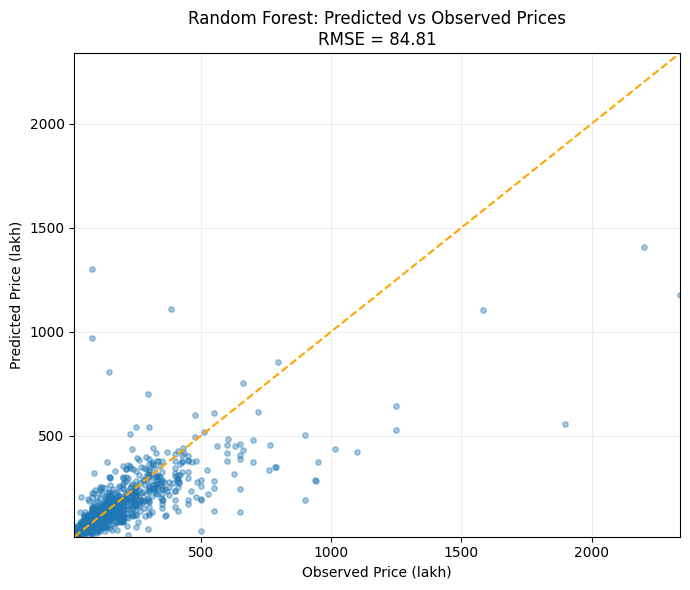

In [ ]:

from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

p = best_pipeline.predict(Xte)

# Combine actual and predicted values to determine axis limits
actual = np.asarray(yte)
predicted = np.asarray(p)

low = min(actual.min(), predicted.min())
high = max(actual.max(), predicted.max())

plt.figure(figsize=(7, 6))
plt.scatter(actual, predicted, alpha=0.4, s=15)

# Perfect prediction reference line
plt.plot([low, high], [low, high], 'orange', linestyle='--')

plt.xlim(low, high)
plt.ylim(low, high)

plt.xlabel("Observed Price (lakh)")
plt.ylabel("Predicted Price (lakh)")
plt.title(
    f"{bn}: Predicted vs Observed Prices\n"
    f"RMSE = {np.sqrt(mean_squared_error(actual, predicted)):.2f}"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig("fig6_pred_vs_obs.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
cnt = Xtr.location.value_counts()
grp = Xte.location.map(lambda l: 'unseen' if l not in cnt else ('rare (<10)' if cnt[l]<10 else 'frequent'))
t = pd.DataFrame({'g':grp,'bhk':Xte.bhk,'err':(yte-p)**2,'perr':(yte-pb)**2})
print(t.groupby('g').agg(n=('err','size'),rmse=('err',lambda x:np.sqrt(x.mean())),base=('perr',lambda x:np.sqrt(x.mean()))))
print(t.groupby('bhk').agg(n=('err','size'),rmse=('err',lambda x:np.sqrt(x.mean()))))
# Feature importance (if RF is best): best['RandomForest'].best_estimator_...

               n        rmse         base
g                                        
frequent    1894   62.126364  1360.600732
rare (<10)   510  103.651444  1537.185379
unseen        94  234.698131   371.113509
         n        rmse
bhk                   
1.0    149   66.361513
2.0   1067   22.341128
3.0    958   55.500075
4.0    241  207.198877
5.0     42  216.372545
6.0     21  154.555219
7.0      9  291.713654
8.0      4   95.643039
9.0      6  177.320323
11.0     1  148.844865


Dataset shape: (13320, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB

Missing values (%):
area_type        0.0
availability     0.0
location         0.0
total_sqft       0.0
price            0.0
size             0.1
bath             0.5
balcony          4.6
society         41.3
dtype: float64


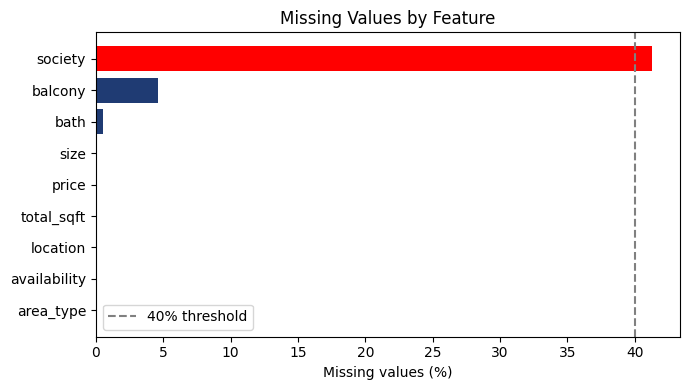


Table 1: Variable Summary


,Variable,Type,Missing %,Unique
0,area_type,object,0.0,4
1,availability,object,0.0,81
2,location,object,0.0,1305
3,size,object,0.1,31
4,society,object,41.3,2688
5,total_sqft,object,0.0,2117
6,bath,float64,0.5,19
7,balcony,float64,4.6,4
8,price,float64,0.0,1994


In [ ]:

import re, warnings, shutil, sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

warnings.filterwarnings("ignore")
RS = 42

# Read the already-uploaded dataset
file_path = "/content/Bengaluru_House_Data.csv"

if not Path(file_path).exists():
    from google.colab import files
    uploaded = files.upload()
    file_path = next(
        (f"/content/{name}" for name in uploaded
         if name.endswith(".csv")),
        None
    )

if file_path is None or not Path(file_path).exists():
    raise FileNotFoundError("Bengaluru_House_Data.csv not found.")

raw = pd.read_csv(file_path)

print("Dataset shape:", raw.shape)
raw.info()

# Missing values analysis
miss = raw.isna().mean().mul(100).round(1).sort_values()

print("\nMissing values (%):")
print(miss)

# Figure 1: Missing values
THRESH = 40

plt.figure(figsize=(7, 4))
plt.barh(
    miss.index,
    miss.values,
    color=[
        'red' if v > THRESH else '#1f3b73'
        for v in miss.values
    ]
)
plt.axvline(THRESH, ls='--', c='gray',
            label=f'{THRESH}% threshold')
plt.xlabel("Missing values (%)")
plt.title("Missing Values by Feature")
plt.legend()
plt.tight_layout()
plt.savefig("fig1_missing.png", dpi=300, bbox_inches="tight")
plt.show()

# Table 1: Dataset variables
t1 = pd.DataFrame({
    'Variable': raw.columns,
    'Type': raw.dtypes.astype(str).values,
    'Missing %': raw.isna().mean().mul(100).round(1).values,
    'Unique': raw.nunique().values
})

t1.to_csv("table1_variables.csv", index=False)

print("\nTable 1: Variable Summary")
display(t1)

In [ ]:
def to_sqft(x):
    try: return float(x)
    except:
        s = str(x)
        if '-' in s:
            a, b = s.split('-')[:2]
            try: return (float(a)+float(b))/2
            except: return np.nan
        m = re.match(r"([\d.]+)\s*(Sq\. Meter|Sq\. Yards|Perch|Acres|Cents|Guntha|Grounds)", s)
        if m:
            f = {'Sq. Meter':10.7639,'Sq. Yards':9,'Perch':272.25,'Acres':43560,
                 'Cents':435.6,'Guntha':1089,'Grounds':2400}[m.group(2)]
            return float(m.group(1))*f
        return np.nan

df = raw.drop(columns=['society']).copy()
df['sqft'] = df['total_sqft'].apply(to_sqft)
df['bhk'] = df['size'].str.extract(r'(\d+)').astype(float)
df['location'] = df['location'].str.strip()
df['ready'] = (df['availability'] == 'Ready To Move').astype(int)
n_start = len(df)
df = df.dropna(subset=['sqft','bhk','price','location'])
print("dropped for unparseable/missing core fields:", n_start-len(df))

def iqr_report(d, tag):
    print(f"--- IQR outlier % ({tag}) ---")
    for c in ['sqft','bhk','bath','balcony','price']:
        q1, q3 = d[c].quantile([.25,.75]); i = q3-q1
        print(c, round(((d[c] < q1-1.5*i) | (d[c] > q3+1.5*i)).mean()*100, 1))

iqr_report(df, "before rules")
n0 = len(df)
df = df[(df['sqft']/df['bhk'] >= 300) & (df['bath'] <= df['bhk']+2)]
print("removed by rules (sqft/bhk<300, bath>bhk+2):", n0-len(df))
iqr_report(df, "after rules")

df['affordable'] = (df['price'] <= 45).astype(int)   # cite an official source for 45 lakh
print("final rows:", len(df), "| affordable share:", df['affordable'].mean().round(3))

dropped for unparseable/missing core fields: 17
--- IQR outlier % (before rules) ---
sqft 8.9
bhk 6.4
bath 7.8
balcony 0.0
price 9.6
removed by rules (sqft/bhk<300, bath>bhk+2): 814
--- IQR outlier % (after rules) ---
sqft 9.1
bhk 3.1
bath 5.4
balcony 0.0
price 10.1
final rows: 12489 | affordable share: 0.202


sqft       0.05
bhk        0.48
bath       0.52
balcony    0.12
price      1.00
Name: price, dtype: float64


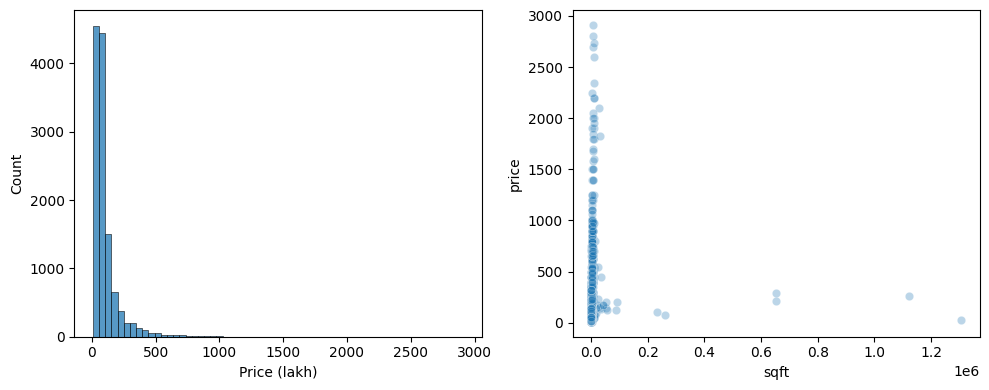

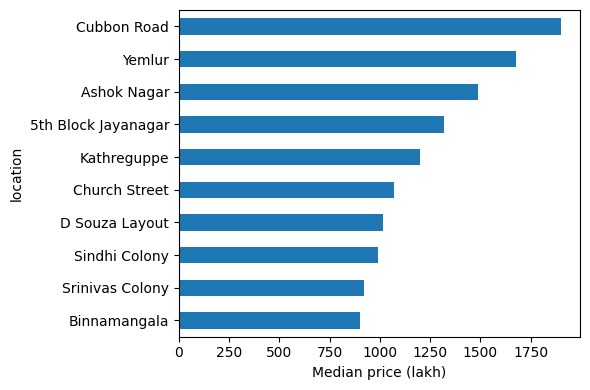

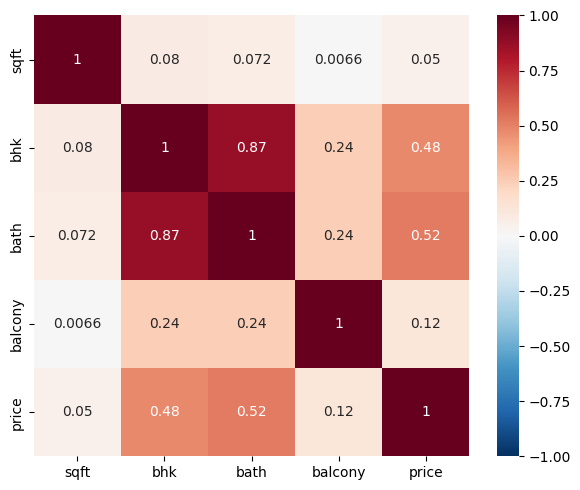

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))
sns.histplot(df.price, bins=60, ax=ax[0]); ax[0].set_xlabel("Price (lakh)")
sns.scatterplot(x='sqft', y='price', data=df, alpha=.3, ax=ax[1])
plt.tight_layout(); plt.savefig("fig2_eda.png", dpi=200)

plt.figure(figsize=(6,4))
df.groupby('location').price.median().nlargest(10).sort_values().plot.barh()
plt.xlabel("Median price (lakh)"); plt.tight_layout()
plt.savefig("fig2b_top_locations.png", dpi=200)

plt.figure(figsize=(6,5))
sns.heatmap(df[['sqft','bhk','bath','balcony','price']].corr(), annot=True, cmap='RdBu_r', vmin=-1, vmax=1)
plt.tight_layout(); plt.savefig("fig3_corr.png", dpi=200)
print(df[['sqft','bhk','bath','balcony','price']].corr()['price'].round(2))

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor as TTR
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import *

class Winsorizer(BaseEstimator, TransformerMixin):
    """Clips each feature to its 1st/99th TRAIN percentiles."""
    def fit(self, X, y=None):
        self.lo_ = np.nanpercentile(X, 1, axis=0); self.hi_ = np.nanpercentile(X, 99, axis=0); return self
    def transform(self, X): return np.clip(X, self.lo_, self.hi_)

num = ['sqft','bhk','bath','balcony','ready']
cat = ['location','area_type']
X = df[num+cat]; y = df['price']; yc = df['affordable']
Xtr, Xte, ytr, yte, yctr, ycte = train_test_split(X, y, yc, test_size=.2, random_state=RS, stratify=yc)
print(len(Xtr), len(Xte))

def prep():
    return ColumnTransformer([
        ('n', Pipeline([('i', SimpleImputer(strategy='median')), ('w', Winsorizer()), ('s', StandardScaler())]), num),
        ('c', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=10, sparse_output=False), cat)])

# Baseline: median Rs/sqft from TRAIN only
ppsf = (ytr*1e5/Xtr.sqft).median()
pb = Xte.sqft*ppsf/1e5
print("baseline Rs/sqft:", round(ppsf))

9991 2498
baseline Rs/sqft: 5285


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor

R = 'm__regressor__'
models = {
 'Linear (OLS)':(LinearRegression(),{}),
 'Ridge':(Ridge(),{R+'alpha':[1,10,100]}),
 'Lasso':(Lasso(max_iter=5000),{R+'alpha':[.001,.01,.1]}),
 'Decision tree':(DecisionTreeRegressor(random_state=RS),{R+'max_depth':[6,10,14],R+'min_samples_leaf':[5,20]}),
 'k-NN':(KNeighborsRegressor(),{R+'n_neighbors':[5,15,31],R+'weights':['uniform','distance']}),
 'SVR (RBF)':(SVR(),{R+'C':[10,100],R+'epsilon':[.05,.2]}),
 'Random forest':(RandomForestRegressor(random_state=RS,n_jobs=-1),{R+'n_estimators':[200],R+'min_samples_leaf':[1,3]}),
 'MLP (64-32)':(MLPRegressor((64,32),early_stopping=True,random_state=RS,max_iter=500),{R+'alpha':[1e-4,1e-2,1]}),
}
kf = KFold(5, shuffle=True, random_state=RS)
rows, best, params = [], {}, []
for name,(est,grid) in models.items():
    pipe = Pipeline([('p',prep()),('m',TTR(regressor=est,func=np.log1p,inverse_func=np.expm1))])
    gs = GridSearchCV(pipe, grid, cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1).fit(Xtr, ytr)
    p_ = gs.predict(Xte); best[name] = gs
    rows.append([name, mean_absolute_error(yte,p_), np.sqrt(mean_squared_error(yte,p_)), r2_score(yte,p_), -gs.best_score_])
    params.append([name, str(grid) if grid else '-', {k.replace(R,''):v for k,v in gs.best_params_.items()} or '-'])
    print(name, "done")

rows.append(['Baseline (median Rs/sqft)', mean_absolute_error(yte,pb), np.sqrt(mean_squared_error(yte,pb)), r2_score(yte,pb), np.nan])
res = pd.DataFrame(rows, columns=['Model','MAE','RMSE','R2','CV-RMSE']).round(3)
print(res.sort_values('RMSE')); res.to_csv("table3_regression.csv", index=False)

t2 = pd.DataFrame(params, columns=['Model','Grid searched','Selected'])
t2.to_csv("table2_hyperparams.csv", index=False); print(t2)

Linear (OLS) done
Ridge done
Lasso done
Decision tree done
k-NN done
SVR (RBF) done
Random forest done
MLP (64-32) done
                       Model     MAE      RMSE      R2  CV-RMSE
7                MLP (64-32)  30.238    83.161   0.636   92.231
4                       k-NN  33.230    88.509   0.588   97.616
6              Random forest  32.112    88.540   0.588   93.357
5                  SVR (RBF)  31.247    90.089   0.573   94.373
3              Decision tree  35.192    93.013   0.545   98.978
1                      Ridge  35.671    95.181   0.523   95.289
0               Linear (OLS)  35.729    95.350   0.522   95.309
2                      Lasso  39.039   101.235   0.461   97.118
8  Baseline (median Rs/sqft)  83.119  1375.219 -98.486      NaN
           Model                                      Grid searched  \
0   Linear (OLS)                                                  -   
1          Ridge              {'m__regressor__alpha': [1, 10, 100]}   
2          Lasso        {'m

In [ ]:
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

clfs = {
 'Logistic regression':(LogisticRegression(max_iter=3000),{'m__C':[.1,1,10],'m__class_weight':[None,'balanced']}),
 'Gaussian NB':(GaussianNB(),{}),
 'Decision tree':(DecisionTreeClassifier(random_state=RS),{'m__max_depth':[4,8,12],'m__class_weight':[None,'balanced']}),
 'k-NN':(KNeighborsClassifier(),{'m__n_neighbors':[5,15,31]}),
 'Perceptron':(Perceptron(random_state=RS),{}),
 'SVM (RBF)':(SVC(random_state=RS),{'m__C':[.1,1,10]}),
 'MLP (64-32)':(MLPClassifier((64,32),early_stopping=True,random_state=RS,max_iter=500),{'m__alpha':[1e-4,1]}),
}
def score(g, X_): return g.predict_proba(X_)[:,1] if hasattr(g,'predict_proba') else g.decision_function(X_)

rows, cb = [], {}
for n,(est,grid) in clfs.items():
    pipe = Pipeline([('p',prep()),('m',est)])
    gs = GridSearchCV(pipe, grid, cv=5, scoring='f1', n_jobs=-1).fit(Xtr, yctr)
    p_ = gs.predict(Xte); cb[n] = gs
    rows.append([n, accuracy_score(ycte,p_), precision_score(ycte,p_), recall_score(ycte,p_), f1_score(ycte,p_), roc_auc_score(ycte,score(gs,Xte))])
    params.append([n, str(grid) if grid else '-', {k.replace('m__',''):v for k,v in gs.best_params_.items()} or '-'])
    print(n, "done")

pbase = (pb <= 45).astype(int)
rows.append(['Baseline', accuracy_score(ycte,pbase), precision_score(ycte,pbase), recall_score(ycte,pbase), f1_score(ycte,pbase), np.nan])
cres = pd.DataFrame(rows, columns=['Model','Acc','Prec','Recall','F1','AUC']).round(3)
print(cres); cres.to_csv("table4_classification.csv", index=False)
pd.DataFrame(params, columns=['Model','Grid searched','Selected']).to_csv("table2_hyperparams.csv", index=False)

Logistic regression done
Gaussian NB done
Decision tree done
k-NN done
Perceptron done
SVM (RBF) done
MLP (64-32) done
                 Model    Acc   Prec  Recall     F1    AUC
0  Logistic regression  0.834  0.556   0.873  0.680  0.924
1          Gaussian NB  0.381  0.241   0.960  0.385  0.600
2        Decision tree  0.805  0.510   0.885  0.647  0.891
3                 k-NN  0.874  0.701   0.655  0.677  0.891
4           Perceptron  0.818  0.620   0.252  0.358  0.798
5            SVM (RBF)  0.886  0.763   0.631  0.691  0.924
6          MLP (64-32)  0.892  0.789   0.637  0.705  0.933
7             Baseline  0.841  0.792   0.288  0.422    NaN


TN,FP,FN,TP: 1908 86 183 321
Lasso zero coefficients: 174 of 215


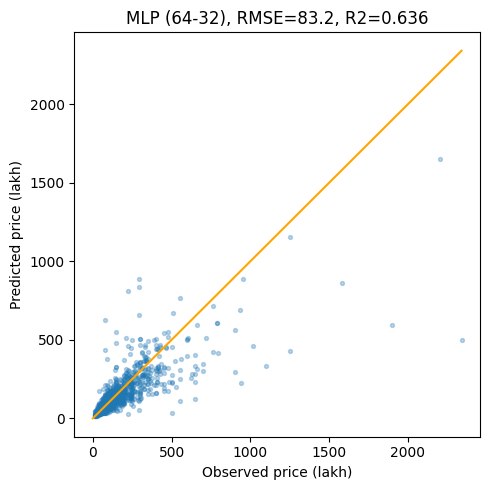

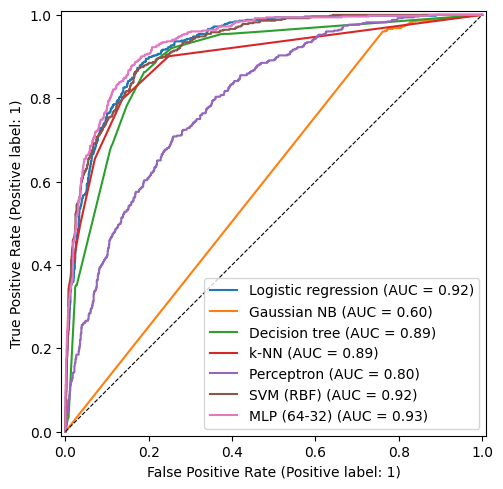

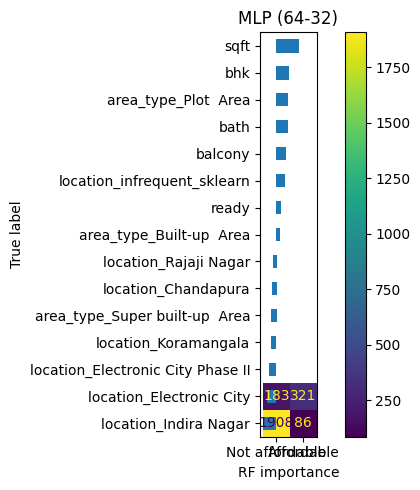

In [ ]:
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

# Fig 6: predicted vs observed (best regressor)
bn = res[~res.Model.str.startswith('Baseline')].sort_values('RMSE').iloc[0].Model
p = best[bn].predict(Xte); lim = max(yte.max(), p.max())
plt.figure(figsize=(5,5)); plt.scatter(yte, p, alpha=.3, s=8); plt.plot([0,lim],[0,lim],'orange')
plt.xlabel("Observed price (lakh)"); plt.ylabel("Predicted price (lakh)")
plt.title(f"{bn}, RMSE={np.sqrt(mean_squared_error(yte,p)):.1f}, R2={r2_score(yte,p):.3f}")
plt.tight_layout(); plt.savefig("fig6_pred_vs_obs.png", dpi=200)

# Fig 7: ROC curves
fig, ax = plt.subplots(figsize=(6,5))
for n,g in cb.items(): RocCurveDisplay.from_estimator(g, Xte, ycte, name=n, ax=ax)
ax.plot([0,1],[0,1],'k--',lw=.8); plt.tight_layout(); plt.savefig("fig7_roc.png", dpi=200)

# Confusion matrix of best classifier (by F1)
bc = cres[cres.Model!='Baseline'].sort_values('F1').iloc[-1].Model
ConfusionMatrixDisplay.from_estimator(cb[bc], Xte, ycte, display_labels=['Not affordable','Affordable'])
plt.title(bc); plt.savefig("fig8_confusion.png", dpi=200)
tn, fp, fn, tp = confusion_matrix(ycte, cb[bc].predict(Xte)).ravel(); print("TN,FP,FN,TP:", tn, fp, fn, tp)

# Feature names after preprocessing
ct = best['Lasso'].best_estimator_.named_steps['p']
names = num + list(ct.named_transformers_['c'].get_feature_names_out(cat))

# Lasso coefficients
coef = pd.Series(best['Lasso'].best_estimator_.named_steps['m'].regressor_.coef_, index=names)
print("Lasso zero coefficients:", (coef==0).sum(), "of", len(coef))
coef.reindex(coef.abs().nlargest(15).index).sort_values().plot.barh(figsize=(6,5))
plt.xlabel("Lasso coefficient (log-price scale)"); plt.tight_layout(); plt.savefig("fig9_lasso.png", dpi=200)

# Random-forest importance
rf = best['Random forest'].best_estimator_.named_steps['m'].regressor_
imp = pd.Series(rf.feature_importances_, index=names)
imp.nlargest(15).sort_values().plot.barh(figsize=(6,5))
plt.xlabel("RF importance"); plt.tight_layout(); plt.savefig("fig10_rf_importance.png", dpi=200)

components for 90%: 13 | for 95%: 55 | PC1: 41.7
                     Setting     MAE     RMSE     R2
0          OLS, all features  35.729   95.350  0.522
1               OLS, PCA 95%  39.222  101.207  0.461
2  k-NN (k=15), all features  33.765   92.014  0.555
3       k-NN (k=15), PCA 95%  34.553   92.529  0.550


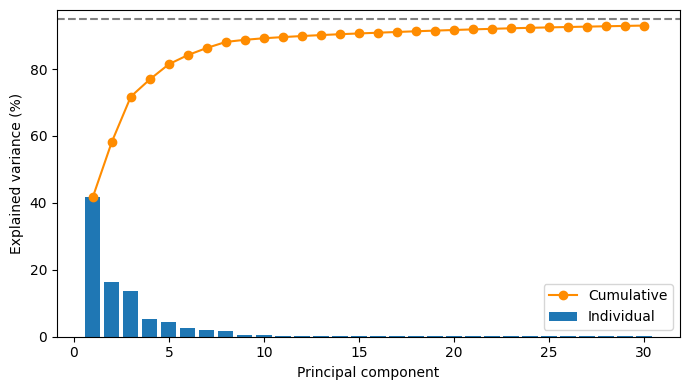

In [ ]:
from sklearn.decomposition import PCA

Z = prep().fit_transform(Xtr)
pca = PCA().fit(Z); ev = pca.explained_variance_ratio_*100; cum = ev.cumsum()
print("components for 90%:", np.argmax(cum>=90)+1, "| for 95%:", np.argmax(cum>=95)+1, "| PC1:", ev[0].round(1))
k = 30
fig, a = plt.subplots(figsize=(7,4))
a.bar(range(1,k+1), ev[:k], label='Individual'); a.plot(range(1,k+1), cum[:k], 'o-', c='darkorange', label='Cumulative')
a.axhline(95, ls='--', c='gray'); a.set_xlabel("Principal component"); a.set_ylabel("Explained variance (%)"); a.legend()
plt.tight_layout(); plt.savefig("fig4_pca.png", dpi=200)

def run(est, use_pca):
    steps = [('p',prep())] + ([('pca',PCA(.95))] if use_pca else []) + [('m',TTR(regressor=est,func=np.log1p,inverse_func=np.expm1))]
    q = Pipeline(steps).fit(Xtr, ytr).predict(Xte)
    return [mean_absolute_error(yte,q), np.sqrt(mean_squared_error(yte,q)), r2_score(yte,q)]

t5 = pd.DataFrame([
  ['OLS, all features']+run(LinearRegression(),False), ['OLS, PCA 95%']+run(LinearRegression(),True),
  ['k-NN (k=15), all features']+run(KNeighborsRegressor(15),False), ['k-NN (k=15), PCA 95%']+run(KNeighborsRegressor(15),True)],
  columns=['Setting','MAE','RMSE','R2']).round(3)
print(t5); t5.to_csv("table5_pca.csv", index=False)

In [ ]:
cnt = Xtr.location.value_counts()
ntr = Xte.location.map(lambda l: cnt.get(l, 0))
grp = ntr.map(lambda n: 'unseen (0)' if n==0 else ('rare (1-9)' if n<10 else 'frequent (10+)'))
T = pd.DataFrame({'loc':Xte.location, 'ntrain':ntr, 'g':grp, 'bhk':Xte.bhk, 'y':yte,
                  'e':(yte-p)**2, 'eb':(yte-pb)**2})
rm = lambda x: np.sqrt(x.mean())

by_group = T.groupby('g').agg(n=('e','size'), RMSE_model=('e',rm), RMSE_baseline=('eb',rm)).round(2)
by_bhk = T.groupby(T.bhk.clip(upper=5)).agg(n=('e','size'), RMSE_model=('e',rm), RMSE_baseline=('eb',rm)).round(2)
print(by_group, "\n", by_bhk)
by_group.to_csv("table_robust_group.csv"); by_bhk.to_csv("table_robust_bhk.csv")

# Table A1: per-location (20 most frequent test locations)
A1 = T.groupby('loc').agg(n_train=('ntrain','first'), n_test=('e','size'), mean_price=('y','mean'),
                          RMSE_model=('e',rm), RMSE_baseline=('eb',rm))
A1 = A1.sort_values('n_test', ascending=False).head(20).round(1)
A1['worse_than_baseline'] = A1.RMSE_model > A1.RMSE_baseline
print(A1); A1.to_csv("tableA1_per_location.csv")
print("Locations where model worse than baseline:", (T.groupby('loc').agg(a=('e',rm), b=('eb',rm)).eval('a>b')).sum())

                   n  RMSE_model  RMSE_baseline
g                                              
frequent (10+)  1894       53.27        1360.60
rare (1-9)       510      129.10        1537.19
unseen (0)        94      190.23         371.11 
         n  RMSE_model  RMSE_baseline
bhk                                 
1.0   149       68.35          67.25
2.0  1067       19.07         165.02
3.0   958       57.12          79.48
4.0   241      201.68         265.55
5.0    83      198.27        7502.21
                          n_train  n_test  mean_price  RMSE_model  \
loc                                                                 
Whitefield                    434     100       112.9        92.6   
Sarjapur  Road                307      81       118.4        66.1   
Electronic City               229      66        51.2        12.3   
Kanakpura Road                209      55        72.3        15.5   
Thanisandra                   184      50        75.2        18.8   
Uttarahalli     

In [ ]:
import platform
print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__, "| seed", RS)
shutil.make_archive("results", "zip", ".", ) if False else None
import glob, zipfile
with zipfile.ZipFile("results.zip","w") as z:
    for f in glob.glob("fig*.png")+glob.glob("table*.csv"): z.write(f)
from google.colab import files; files.download("results.zip")

Python 3.13.16 | scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.1.3 | seed 42


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

uploaded = files.upload()
# After uploading, you will be able to run your robustness analysis cell below.

Saving Bengaluru_House_Data.csv to Bengaluru_House_Data (1).csv


In [ ]:

import os
import re
import numpy as np
import pandas as pd

from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split

RS = 42

# --------------------------------------------------
# 1. Define Winsorizer
# --------------------------------------------------
class Winsorizer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.lo_ = np.nanpercentile(X, 1, axis=0)
        self.hi_ = np.nanpercentile(X, 99, axis=0)
        return self

    def transform(self, X):
        return np.clip(X, self.lo_, self.hi_)


# --------------------------------------------------
# 2. Define preprocessing pipeline
# --------------------------------------------------
def prep():
    num = ['sqft', 'bhk', 'bath', 'balcony', 'ready']
    cat = ['location', 'area_type']

    return ColumnTransformer([
        ('n', Pipeline([
            ('i', SimpleImputer(strategy='median')),
            ('w', Winsorizer()),
            ('s', StandardScaler())
        ]), num),

        ('c', Pipeline([
            ('i', SimpleImputer(strategy='most_frequent')),
            ('o', OneHotEncoder(
                handle_unknown='infrequent_if_exist',
                min_frequency=10,
                sparse_output=False
            ))
        ]), cat)
    ])


# --------------------------------------------------
# 3. Find and load a valid CSV file
# --------------------------------------------------
file_candidates = [
    'Bengaluru_House_Data.csv',
    '/content/Bengaluru_House_Data.csv'
]

file_name = next(
    (f for f in file_candidates
     if os.path.isfile(f) and os.path.getsize(f) > 0),
    None
)

if file_name is None:
    try:
        from google.colab import files
        uploaded = files.upload()

        file_name = next(
            (f for f in uploaded
             if f.lower().endswith('.csv')
             and os.path.getsize(f) > 0),
            None
        )
    except ImportError:
        file_name = None

if file_name is None:
    raise FileNotFoundError(
        "No non-empty CSV found. Upload the original "
        "Bengaluru_House_Data.csv downloaded from Kaggle."
    )

df = pd.read_csv(file_name)

if df.empty or len(df.columns) == 0:
    raise ValueError(
        "The CSV contains no readable data. "
        "Download the original dataset again."
    )

print("Dataset loaded:", file_name)
print("Original shape:", df.shape)


# --------------------------------------------------
# 4. Convert total_sqft into numerical square feet
# --------------------------------------------------
def to_sqft(x):
    try:
        return float(x)
    except (ValueError, TypeError):
        s = str(x).strip()

        # Handle ranges such as 1000-1200
        if '-' in s:
            try:
                a, b = s.split('-')[:2]
                return (float(a) + float(b)) / 2
            except (ValueError, TypeError):
                pass

        # Handle alternative measurement units
        m = re.match(
            r'([\d.]+)\s*\*?\s*'
            r'(Sq\. Meter|Sq\. Yards|Perch|Acres|Cents|Guntha|Grounds)',
            s
        )

        if m:
            factors = {
                'Sq. Meter': 10.7639,
                'Sq. Yards': 9,
                'Perch': 272.25,
                'Acres': 43560,
                'Cents': 435.6,
                'Guntha': 1089,
                'Grounds': 2400
            }
            return float(m.group(1)) * factors[m.group(2)]

        return np.nan


# --------------------------------------------------
# 5. Clean and prepare the dataset
# --------------------------------------------------
df = df.drop(columns=['society'], errors='ignore').copy()

required = [
    'total_sqft', 'size', 'location', 'availability',
    'price', 'bath', 'balcony', 'area_type'
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Dataset is missing columns: {missing}")

df['sqft'] = df['total_sqft'].apply(to_sqft)

df['bhk'] = pd.to_numeric(
    df['size'].astype(str).str.extract(r'(\d+)')[0],
    errors='coerce'
)

df['location'] = df['location'].astype('string').str.strip()
df['area_type'] = df['area_type'].astype('string').str.strip()

df['ready'] = (
    df['availability'].astype(str).str.strip() == 'Ready To Move'
).astype(int)

for col in ['price', 'bath', 'balcony']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df = df.dropna(
    subset=['sqft', 'bhk', 'price', 'location', 'area_type']
).copy()

df = df[
    (df['sqft'] > 0) &
    (df['bhk'] > 0) &
    (df['price'] > 0) &
    (df['sqft'] / df['bhk'] >= 300) &
    (df['bath'].isna() | (df['bath'] <= df['bhk'] + 2))
].copy()

if df.empty:
    raise ValueError("No records remain after data cleaning.")

# Affordability threshold: ₹45 lakh
df['affordable'] = (df['price'] <= 45).astype(int)

num = ['sqft', 'bhk', 'bath', 'balcony', 'ready']
cat = ['location', 'area_type']

X = df[num + cat]
y = df['price']
yc = df['affordable']

if yc.nunique() < 2 or yc.value_counts().min() < 2:
    raise ValueError(
        "Not enough examples in both affordability classes "
        "for a stratified train/test split."
    )

Xtr, Xte, ytr, yte, yctr, ycte = train_test_split(
    X, y, yc,
    test_size=0.2,
    random_state=RS,
    stratify=yc
)

print("Cleaned dataset shape:", df.shape)
print("Training records:", len(Xtr))
print("Testing records:", len(Xte))


# --------------------------------------------------
# 6. Train the MLP regression model
# --------------------------------------------------
best_mlp = Pipeline([
    ('p', prep()),
    ('m', TransformedTargetRegressor(
        regressor=MLPRegressor(
            hidden_layer_sizes=(64, 32),
            alpha=0.0001,
            early_stopping=True,
            random_state=RS,
            max_iter=500
        ),
        func=np.log1p,
        inverse_func=np.expm1
    ))
])

best_mlp.fit(Xtr, ytr)
p = best_mlp.predict(Xte)

# Avoid negative predicted house prices
p = np.maximum(p, 0)

print("MLP model trained successfully.")


# --------------------------------------------------
# 7. Generate Table 6: Location-wise Robustness
# --------------------------------------------------
T = pd.DataFrame({
    'loc': Xte['location'].to_numpy(),
    'y': yte.to_numpy(),
    'p': np.asarray(p)
})

T['ae'] = (T['y'] - T['p']).abs()
T['e'] = (T['y'] - T['p']) ** 2

# Five most frequent locations in the test set
top5 = T['loc'].value_counts().head(5).index

rows = []

for loc in top5:
    s = T[T['loc'] == loc]

    rows.append([
        loc,
        len(s),
        s['ae'].mean(),
        np.sqrt(s['e'].mean())
    ])

# Aggregate all remaining locations
other = T[~T['loc'].isin(top5)]

if not other.empty:
    rows.append([
        'Other evaluated locations',
        len(other),
        other['ae'].mean(),
        np.sqrt(other['e'].mean())
    ])

t6 = pd.DataFrame(
    rows,
    columns=[
        'Location',
        'Number of test properties',
        'MAE (₹ lakh) ↓',
        'RMSE (₹ lakh) ↓'
    ]
).round(2)

print("\nTABLE 6: LOCATION-WISE ROBUSTNESS ANALYSIS")
display(t6)

# Save table
output_file = 'table6_location_robustness.csv'
t6.to_csv(output_file, index=False)

print("Table saved to:", output_file)

# Download the CSV in Google Colab
try:
    from google.colab import files
    files.download(output_file)
except ImportError:
    pass


Saving Bengaluru_House_Data.csv to Bengaluru_House_Data (2).csv
Dataset loaded: Bengaluru_House_Data (2).csv
Original shape: (13320, 9)
Cleaned dataset shape: (12546, 12)
Training records: 10036
Testing records: 2510
MLP model trained successfully.

TABLE 6: LOCATION-WISE ROBUSTNESS ANALYSIS


,Location,Number of test properties,MAE (₹ lakh) ↓,RMSE (₹ lakh) ↓
0,Whitefield,103,22.37,39.38
1,Sarjapur Road,86,28.16,54.58
2,Electronic City,59,10.14,13.19
3,Thanisandra,46,22.89,47.01
4,Kanakpura Road,43,9.24,14.85
5,Other evaluated locations,2173,34.02,100.74


Table saved to: table6_location_robustness.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

components for 90%: 13 | components for 95%: 56 | PC1 explains: 41.7 %
                     Setting     MAE    RMSE     R2
0          OLS, all features  35.703  93.154  0.618
1               OLS, PCA 95%  39.232  99.225  0.567
2  k-NN (k=15), all features  35.199  99.184  0.567
3       k-NN (k=15), PCA 95%  36.038  99.393  0.565


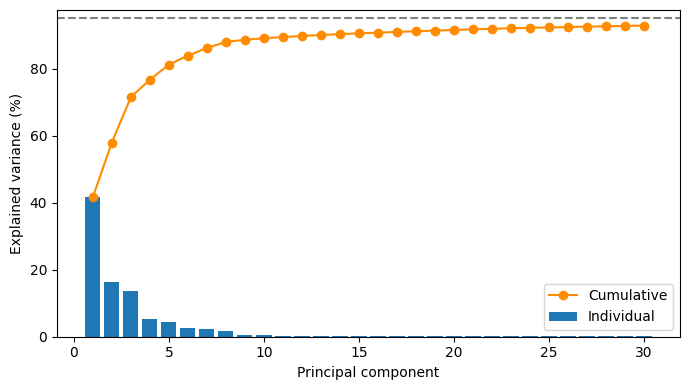

In [ ]:
from sklearn.decomposition import PCA

Z = prep().fit_transform(Xtr)
pca = PCA().fit(Z)
ev = pca.explained_variance_ratio_ * 100
cum = ev.cumsum()
print("components for 90%:", np.argmax(cum >= 90) + 1,
      "| components for 95%:", np.argmax(cum >= 95) + 1,
      "| PC1 explains:", ev[0].round(1), "%")

# Fig 4
k = min(30, len(ev))
fig, a = plt.subplots(figsize=(7, 4))
a.bar(range(1, k+1), ev[:k], label='Individual')
a.plot(range(1, k+1), cum[:k], 'o-', c='darkorange', label='Cumulative')
a.axhline(95, ls='--', c='gray')
a.set_xlabel("Principal component"); a.set_ylabel("Explained variance (%)"); a.legend()
plt.tight_layout(); plt.savefig("fig4_pca.png", dpi=200)

# Table 5
def run(est, use_pca):
    steps = [('p', prep())] + ([('pca', PCA(.95))] if use_pca else []) + \
            [('m', TTR(regressor=est, func=np.log1p, inverse_func=np.expm1))]
    q = Pipeline(steps).fit(Xtr, ytr).predict(Xte)
    return [mean_absolute_error(yte, q), np.sqrt(mean_squared_error(yte, q)), r2_score(yte, q)]

t5 = pd.DataFrame([
    ['OLS, all features'] + run(LinearRegression(), False),
    ['OLS, PCA 95%'] + run(LinearRegression(), True),
    ['k-NN (k=15), all features'] + run(KNeighborsRegressor(15), False),
    ['k-NN (k=15), PCA 95%'] + run(KNeighborsRegressor(15), True)],
    columns=['Setting', 'MAE', 'RMSE', 'R2']).round(3)
print(t5); t5.to_csv("table5_pca.csv", index=False)